# Walmart Hurricane Project: Maryam Ahmed

# 1. Walmart Transactions — Data Cleaning & Decision Log

Cleaning walmart_transactions.csv below

Step 1: Loading dataset

In [1]:
import pandas as pd
# the original Walmart transactions dataset
url = "https://raw.githubusercontent.com/marykahmed77-cmd/walmart-hurricane-project/main/data/walmart_transactions.csv"
df = pd.read_csv(url)
# preserving the original dataset
df_original = df.copy()
print("Original dataset shape:", df.shape)
display(df.head())

Original dataset shape: (25562, 8)


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-13T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-02 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-06 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-30 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-15 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


Step 2: look at the original dataset

In [2]:
# examining dataset structure
df.info()
# checking for missing values
print("\nMissing values:")
print(df.isnull().sum())
# checking for duplicate rows
print("\nExact duplicates:", df.duplicated().sum())
# checking for unique values
print("\nUnique store IDs:", df["store_id"].nunique())
print("Unique SKUs:", df["sku"].nunique())
print("Unique product names:", df["product_name"].nunique())
print("Unique categories:", df["category"].nunique())
# checking quantity distribution
print("\nQuantity statistics:")
print(df["quantity"].describe())
# looking for negative quantities
print("\nNegative quantities:", (df["quantity"] < 0).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25562 entries, 0 to 25561
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   transaction_id  25562 non-null  object
 1   store_id        25562 non-null  object
 2   timestamp       24676 non-null  object
 3   sku             25562 non-null  object
 4   product_name    25562 non-null  object
 5   category        25562 non-null  object
 6   quantity        25562 non-null  int64 
 7   unit_price      25562 non-null  object
dtypes: int64(1), object(7)
memory usage: 1.6+ MB

Missing values:
transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64

Exact duplicates: 30

Unique store IDs: 60
Unique SKUs: 45
Unique product names: 63
Unique categories: 37

Quantity statistics:
count    25562.000000
mean         1.932634
std          1.086926
m

step 3: making the cleaning function

In [3]:
# Standard category names
CATEGORY_MAP = {
    "grocery": "Grocery",
    "groceries": "Grocery",
    "household": "Household",
    "household essentials": "Household",
    "electronics": "Electronics",
    "alcohol": "Alcohol",
    "alcoholic beverages": "Alcohol",
    "snacks": "Snacks",
    "emergency": "Emergency",
    "emergency supplies": "Emergency",
    "entertainment": "Entertainment",
    "games & entertainment": "Entertainment",
    "health": "Health",
    "health & wellness": "Health",
    "breakfast": "Breakfast",
    "breakfast foods": "Breakfast",
    "baby": "Baby",
    "baby products": "Baby"
}

def clean_transactions(raw):
    # Work on a copy so original data remains unchanged
    df_clean = raw.copy()
    decision_log = []

    def log_decision(issue, action, reason, count, status="Applied"):
        decision_log.append({
            "Issue": issue,
            "Cleaning Decision": action,
            "Justification": reason,
            "Rows Affected": int(count),
            "Status": status
        })

    # 1. Remove exact duplicate records
    duplicate_count = df_clean.duplicated().sum()
    df_clean = df_clean.drop_duplicates().copy()

    log_decision(
        "Exact duplicate records",
        "Remove exact duplicate rows",
        "Prevent double-counting identical transactions",
        duplicate_count
    )

    # 2. Standardize store IDs
    old_store_ids = df_clean["store_id"].copy()

    df_clean["store_id"] = (
        df_clean["store_id"]
        .astype("string")
        .str.strip()
        .str.upper()
        .str.replace("_", "-", regex=False)
        .str.replace(r"^FL(\d{3})$", r"FL-\1", regex=True)
    )

    changed_store_ids = (
        old_store_ids.astype("string") != df_clean["store_id"]
    ).sum()

    log_decision(
        "Inconsistent store IDs",
        "Standardize capitalization, spaces and hyphens",
        "Create consistent identifiers for merging with store data",
        changed_store_ids
    )

    # 3. Convert unit prices to numeric
    original_prices = df_clean["unit_price"].astype("string")

    formatted_prices = original_prices.str.contains(
        r"[$,]", regex=True, na=False
    ).sum()

    df_clean["unit_price"] = pd.to_numeric(
        original_prices
        .str.strip()
        .str.replace(r"[$,]", "", regex=True),
        errors="coerce"
    )

    log_decision(
        "Unit prices stored as text",
        "Remove dollar signs and commas; convert to numeric",
        "Allow accurate price and revenue calculations",
        formatted_prices
    )

    # Check for prices that could not be converted
    invalid_prices = df_clean["unit_price"].isna().sum()

    log_decision(
        "Unparseable unit prices",
        "Flag missing or unparseable numeric prices",
        "Avoid introducing incorrect zero-dollar transactions",
        invalid_prices,
        "Review" if invalid_prices else "Checked: none"
    )

    # 4 standardizing timestamps
    df_clean["timestamp"] = pd.to_datetime(
        df_clean["timestamp"],
        format="mixed",
        errors="coerce"
    )

    df_clean["missing_timestamp"] = df_clean["timestamp"].isna()


    log_decision(
    "Mixed timestamp formats",
    "Parse nonmissing timestamps into a consistent datetime format",
    "Standardize timestamps for daily sales and hurricane timeline analysis. "
    "The count represents successfully parsed timestamps, including dates "
    "that may already have been in a valid format.",
    df_clean["timestamp"].notna().sum(),
    "Applied"
)


    log_decision(
        "Missing timestamps",
        "Retain records and flag missing timestamps",
        "Preserve transactions without inventing dates",
        df_clean["missing_timestamp"].sum(),
        "Flagged"
    )

    # 5 standardizing product categories
    original_categories = df_clean["category"].copy()

    normalized_categories = (
        df_clean["category"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    # checking that every category has a mapping
    unknown_categories = (
        set(normalized_categories.dropna().unique())
        - set(CATEGORY_MAP)
    )

    if unknown_categories:
        raise ValueError(
            f"Unmapped categories: {unknown_categories}"
        )

    df_clean["category"] = normalized_categories.map(CATEGORY_MAP)

    changed_categories = (
        original_categories.astype("string") !=
        df_clean["category"]
    ).sum()

    log_decision(
        "Inconsistent category labels",
        "Standardize capitalization and equivalent categories",
        "Prevent equivalent categories from being counted separately",
        changed_categories
    )


# 6 flagging negative quantities
    df_clean["negative_quantity"] = df_clean["quantity"] < 0

    log_decision(
      "Negative transaction quantities",
      "Retain original quantities and flag all negative values",
      "Negative quantities range from -1 to -5 and may represent returns, "
      "transaction adjustments, or data-entry errors. Their meaning cannot "
      "be verified from the available data, so retaining and flagging them "
      "preserves the original records without introducing unsupported corrections. "
      "Sales calculations therefore represent net quantities.",
      df_clean["negative_quantity"].sum(),
      "Retained and flagged; interpretation unverified"
  )


    # 7 preserving SKUs until product catalog verification
    log_decision(
      "Inconsistent product names and SKUs",
      "Preserve original SKU identifiers in cleaned transactions; "
      "use proposed canonical mappings for product-level analysis",
      "Original SKU identifiers are retained to preserve transaction-level "
      "traceability. Question 2 proposes consolidating potentially equivalent "
      "products based on names and package sizes. These mappings are used "
     "for analysis and require verification before permanent consolidation.",
      df_clean.shape[0],
      "Original SKUs preserved; proposed mappings pending verification"
  )


    return df_clean, pd.DataFrame(decision_log)


# Run the cleaning function
df_clean, decision_log = clean_transactions(df_original)

print("Cleaning complete!")
print("Original rows:", len(df_original))
print("Cleaned rows:", len(df_clean))


Cleaning complete!
Original rows: 25562
Cleaned rows: 25532


step 4: verifying the cleaning

In [4]:
print("CLEANING VERIFICATION")
print("Original rows:", len(df_original))
print("Cleaned rows:", len(df_clean))
print("\nRemaining exact duplicates:")
print(df_clean.duplicated().sum())
print("\nUnique store IDs:")
print(df_clean["store_id"].nunique())
print("\nMissing timestamps:")
print(df_clean["missing_timestamp"].sum())
print("\nNegative quantities flagged:")
print(df_clean["negative_quantity"].sum())
print("\nUnparseable prices:")
print(df_clean["unit_price"].isna().sum())
print("\nRemaining categories:")
print(sorted(df_clean["category"].dropna().unique()))
print("\nCleaned data types:")
print(df_clean.dtypes)
# confirming that rows were only removed for exact duplicates
assert len(df_clean) == (
    len(df_original) - df_original.duplicated().sum()
)
assert df_clean.duplicated().sum() == 0
print("\nBasic verification passed!")

CLEANING VERIFICATION
Original rows: 25562
Cleaned rows: 25532

Remaining exact duplicates:
0

Unique store IDs:
12

Missing timestamps:
884

Negative quantities flagged:
130

Unparseable prices:
0

Remaining categories:
['Alcohol', 'Baby', 'Breakfast', 'Electronics', 'Emergency', 'Entertainment', 'Grocery', 'Health', 'Household', 'Snacks']

Cleaned data types:
transaction_id               object
store_id             string[python]
timestamp            datetime64[ns]
sku                          object
product_name                 object
category                     object
quantity                      int64
unit_price                  Float64
missing_timestamp              bool
negative_quantity              bool
dtype: object

Basic verification passed!


step 5: reviewing decision log

In [5]:
# displaying all cleaning decisions
display(decision_log)
# checking the number of documented decisions
print("Total decisions documented:", len(decision_log))

,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicate records,Remove exact duplicate rows,Prevent double-counting identical transactions,30,Applied
1,Inconsistent store IDs,"Standardize capitalization, spaces and hyphens",Create consistent identifiers for merging with...,4345,Applied
2,Unit prices stored as text,Remove dollar signs and commas; convert to num...,Allow accurate price and revenue calculations,3026,Applied
3,Unparseable unit prices,Flag missing or unparseable numeric prices,Avoid introducing incorrect zero-dollar transa...,0,Checked: none
4,Mixed timestamp formats,Parse nonmissing timestamps into a consistent ...,Standardize timestamps for daily sales and hur...,24648,Applied
5,Missing timestamps,Retain records and flag missing timestamps,Preserve transactions without inventing dates,884,Flagged
6,Inconsistent category labels,Standardize capitalization and equivalent cate...,Prevent equivalent categories from being count...,18744,Applied
7,Negative transaction quantities,Retain original quantities and flag all negati...,Negative quantities range from -1 to -5 and ma...,130,Retained and flagged; interpretation unverified
8,Inconsistent product names and SKUs,Preserve original SKU identifiers in cleaned t...,Original SKU identifiers are retained to prese...,25532,Original SKUs preserved; proposed mappings pen...


Total decisions documented: 9


step 5a: correcting some log entries

In [6]:
# clarifying timestamp conversion count
decision_log.loc[4, "Issue"] = "Timestamp parsing"
decision_log.loc[4, "Cleaning Decision"] = (
    "Parse 24,648 non-missing timestamps into datetime format"
)
decision_log.loc[4, "Justification"] = (
    "Enable consistent time-based analysis; count reflects successful parsing"
)

# clarifying pending SKU consolidation
decision_log.loc[8, "Cleaning Decision"] = (
    "No SKU changes made; awaiting product catalog validation"
)
decision_log.loc[8, "Rows Affected"] = 0
decision_log.loc[8, "Status"] = "Pending catalog review"
display(decision_log)

,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicate records,Remove exact duplicate rows,Prevent double-counting identical transactions,30,Applied
1,Inconsistent store IDs,"Standardize capitalization, spaces and hyphens",Create consistent identifiers for merging with...,4345,Applied
2,Unit prices stored as text,Remove dollar signs and commas; convert to num...,Allow accurate price and revenue calculations,3026,Applied
3,Unparseable unit prices,Flag missing or unparseable numeric prices,Avoid introducing incorrect zero-dollar transa...,0,Checked: none
4,Timestamp parsing,"Parse 24,648 non-missing timestamps into datet...",Enable consistent time-based analysis; count r...,24648,Applied
5,Missing timestamps,Retain records and flag missing timestamps,Preserve transactions without inventing dates,884,Flagged
6,Inconsistent category labels,Standardize capitalization and equivalent cate...,Prevent equivalent categories from being count...,18744,Applied
7,Negative transaction quantities,Retain original quantities and flag all negati...,Negative quantities range from -1 to -5 and ma...,130,Retained and flagged; interpretation unverified
8,Inconsistent product names and SKUs,No SKU changes made; awaiting product catalog ...,Original SKU identifiers are retained to prese...,0,Pending catalog review


# 2. Product Catalog — Data Cleaning & Decision Log


step 1: loading product_catalog from github

In [7]:
import pandas as pd

# loading Product Catalog dataset from GitHub
product_url = "https://raw.githubusercontent.com/marykahmed77-cmd/walmart-hurricane-project/main/data/product_catalog.csv"
df_product = pd.read_csv(product_url)
# preserving the original dataset
df_product_original = df_product.copy()
# preview the dataset
print("Original dataset shape:", df_product.shape)
display(df_product.head())

Original dataset shape: (45, 7)


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack


step 2: examine product catalog

In [8]:
# checking dataset structure and data types
df_product.info()
# checking missing values
print("\nMissing values:")
print(df_product.isnull().sum())
# checking exact duplicates
print("\nExact duplicates:", df_product.duplicated().sum())
# checking unique values
print("\nUnique SKUs:", df_product["sku"].nunique())
print("Unique product names:", df_product["product_name"].nunique())
print("Unique categories:", df_product["category"].nunique())
print("Unique subcategories:", df_product["subcategory"].nunique())
print("Unique suppliers:", df_product["supplier"].nunique())
print("Unique package sizes:", df_product["package_size"].nunique())
# Examining category variations
print("\nCategory values:")
print(df_product["category"].value_counts(dropna=False))
# Examining package size variations
print("\nPackage size values:")
print(df_product["package_size"].value_counts(dropna=False))
# checking unit costs
print("\nUnit cost statistics:")
print(df_product["unit_cost"].describe())
# checking duplicate SKU identifiers
print("\nDuplicate SKUs:", df_product["sku"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sku           45 non-null     object 
 1   product_name  45 non-null     object 
 2   category      45 non-null     object 
 3   subcategory   32 non-null     object 
 4   unit_cost     40 non-null     float64
 5   supplier      45 non-null     object 
 6   package_size  45 non-null     object 
dtypes: float64(1), object(6)
memory usage: 2.6+ KB

Missing values:
sku              0
product_name     0
category         0
subcategory     13
unit_cost        5
supplier         0
package_size     0
dtype: int64

Exact duplicates: 0

Unique SKUs: 45
Unique product names: 38
Unique categories: 27
Unique subcategories: 19
Unique suppliers: 14
Unique package sizes: 15

Category values:
category
Emergency              5
Emergency Supplies     3
EMERGENCY              3
ENTERTAINMENT          3
GROCERY      

step 3: cleaning product_catalog

In [9]:
import pandas as pd
import re
def clean_product_catalog(raw):
    df_product_clean = raw.copy()
    product_log = []

    def log(issue, action, reason, count, status="Applied"):
        product_log.append({
            "Issue": issue,
            "Cleaning Decision": action,
            "Justification": reason,
            "Rows Affected": int(count),
            "Status": status
        })

    # 1 removing exact duplicates
    duplicates = df_product_clean.duplicated().sum()
    df_product_clean = df_product_clean.drop_duplicates().copy()

    log(
        "Exact duplicates",
        "Remove exact duplicate records",
        "Prevent duplicate catalog entries",
        duplicates,
        "Applied" if duplicates else "Checked: none"
    )

    # 2 standarize category labels
    category_map = {
        "grocery": "Grocery",
        "groceries": "Grocery",
        "household": "Household",
        "household essentials": "Household",
        "electronics": "Electronics",
        "alcohol": "Alcohol",
        "alcoholic beverages": "Alcohol",
        "snacks": "Snacks",
        "emergency": "Emergency",
        "emergency supplies": "Emergency",
        "entertainment": "Entertainment",
        "games & entertainment": "Entertainment",
        "health": "Health",
        "health & wellness": "Health",
        "breakfast": "Breakfast",
        "breakfast foods": "Breakfast",
        "baby": "Baby",
        "baby products": "Baby"
    }

    old_categories = df_product_clean["category"].copy()

    categories = (
        df_product_clean["category"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    unknown = set(categories.dropna()) - set(category_map)
    if unknown:
        raise ValueError(f"Unmapped categories: {unknown}")

    df_product_clean["category"] = categories.map(category_map)

    changed = (
        old_categories.astype("string") !=
        df_product_clean["category"]
    ).sum()

    log(
        "Inconsistent categories",
        "Standardize category names to match transactions",
        "Ensure consistent grouping and joins",
        changed
    )

    # 3. Standardize product name formatting
    old_names = df_product_clean["product_name"].copy()

    df_product_clean["product_name"] = (
        df_product_clean["product_name"]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

    changed_names = (
        old_names.astype("string") !=
        df_product_clean["product_name"]
    ).sum()

    log(
        "Inconsistent product name formatting",
        "Standardize whitespace and title capitalization",
        "Improve consistency without merging product identities",
        changed_names
    )

    # 4 standarize package-size formatting
    old_packages = df_product_clean["package_size"].copy()

    def clean_package(value):
        if pd.isna(value):
            return pd.NA

        value = str(value).strip().lower()
        value = value.replace("–", "-").replace("—", "-")

        if value in ["single", "bundle"]:
            return value

        match = re.fullmatch(
            r"(\d+)\s*-?\s*(?:pack|pk)",
            value
        )

        if match:
            return f"{int(match.group(1))}-pack"

        return value

    df_product_clean["package_size"] = (
        df_product_clean["package_size"].apply(clean_package)
    )

    changed_packages = (
        old_packages.astype("string") !=
        df_product_clean["package_size"].astype("string")
    ).sum()

    log(
        "Inconsistent package-size formats",
        "Standardize numeric pack labels to N-pack",
        "Make equivalent packaging formats consistent",
        changed_packages
    )

    # 5 checking and flag missing unit costs
    df_product_clean["unit_cost"] = pd.to_numeric(
        df_product_clean["unit_cost"],
        errors="coerce"
    )

    df_product_clean["missing_unit_cost"] = (
        df_product_clean["unit_cost"].isna()
    )

    log(
        "Missing unit costs",
        "Retain and flag records with missing costs",
        "Avoid inventing supplier or product costs",
        df_product_clean["missing_unit_cost"].sum(),
        "Flagged"
    )

    # 6 checking duplicate SKUs
    duplicate_skus = df_product_clean["sku"].duplicated().sum()

    log(
        "Duplicate SKU identifiers",
        "Check SKU uniqueness; preserve distinct identifiers",
        "Avoid incorrectly combining different product records",
        duplicate_skus,
        "Review" if duplicate_skus else "Checked: none"
    )

    # 7 preserving supplier information
    log(
        "Supplier inconsistencies",
        "Retain original supplier values pending verification",
        "Supplier identity cannot be inferred from product name",
        0,
        "Pending review"
    )

    # 8 preserving SKU mappings
    log(
        "Potentially equivalent product SKUs",
        "Keep original SKUs pending pack-size and cost review",
        "Prevent incorrect merging of distinct catalog items",
        0,
        "Pending SKU review"
    )

    return df_product_clean, pd.DataFrame(product_log)


df_product_clean, product_decision_log = (
    clean_product_catalog(df_product_original)
)
print("Cleaning complete!")
print("Original rows:", len(df_product_original))
print("Cleaned rows:", len(df_product_clean))

Cleaning complete!
Original rows: 45
Cleaned rows: 45


step 4: verifying cleaning

In [10]:
print("PRODUCT CATALOG CLEANING VERIFICATION")
print("Original rows:", len(df_product_original))
print("Cleaned rows:", len(df_product_clean))
print("\nRemaining exact duplicates:")
print(df_product_clean.duplicated().sum())
print("\nUnique SKUs:")
print(df_product_clean["sku"].nunique())
print("\nMissing unit costs:")
print(df_product_clean["missing_unit_cost"].sum())
print("\nStandardized categories:")
print(sorted(df_product_clean["category"].dropna().unique()))
print("\nStandardized package sizes:")
print(sorted(df_product_clean["package_size"].dropna().unique()))
print("\nCleaned data types:")
print(df_product_clean.dtypes)
# verifying that records were preserved
assert len(df_product_clean) == 45
assert df_product_clean["sku"].nunique() == 45
assert df_product_clean.duplicated().sum() == 0
print("\nBasic verification passed!")

PRODUCT CATALOG CLEANING VERIFICATION
Original rows: 45
Cleaned rows: 45

Remaining exact duplicates:
0

Unique SKUs:
45

Missing unit costs:
5

Standardized categories:
['Alcohol', 'Baby', 'Breakfast', 'Electronics', 'Emergency', 'Entertainment', 'Grocery', 'Health', 'Household', 'Snacks']

Standardized package sizes:
['1-pack', '12-pack', '24-pack', '4-pack', '6-pack', 'bundle', 'single']

Cleaned data types:
sku                          object
product_name         string[python]
category                     object
subcategory                  object
unit_cost                   float64
supplier                     object
package_size                 object
missing_unit_cost              bool
dtype: object

Basic verification passed!


step 5: Product catalog decision log

In [11]:
display(product_decision_log)
print("Total decisions documented:", len(product_decision_log))

,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicates,Remove exact duplicate records,Prevent duplicate catalog entries,0,Checked: none
1,Inconsistent categories,Standardize category names to match transactions,Ensure consistent grouping and joins,32,Applied
2,Inconsistent product name formatting,Standardize whitespace and title capitalization,Improve consistency without merging product id...,18,Applied
3,Inconsistent package-size formats,Standardize numeric pack labels to N-pack,Make equivalent packaging formats consistent,26,Applied
4,Missing unit costs,Retain and flag records with missing costs,Avoid inventing supplier or product costs,5,Flagged
5,Duplicate SKU identifiers,Check SKU uniqueness; preserve distinct identi...,Avoid incorrectly combining different product ...,0,Checked: none
6,Supplier inconsistencies,Retain original supplier values pending verifi...,Supplier identity cannot be inferred from prod...,0,Pending review
7,Potentially equivalent product SKUs,Keep original SKUs pending pack-size and cost ...,Prevent incorrect merging of distinct catalog ...,0,Pending SKU review


Total decisions documented: 8


step 5a: adding the missing subcategories to decision log

In [12]:
missing_subcategories = df_product_clean["subcategory"].isna().sum()
# adding missing subcategory decision to log
product_decision_log = pd.concat([
    product_decision_log,
    pd.DataFrame([{
        "Issue": "Missing subcategories",
        "Cleaning Decision": "Retain missing values pending verification",
        "Justification": "Avoid assigning unsupported product classifications",
        "Rows Affected": int(missing_subcategories),
        "Status": "Flagged"
    }])
], ignore_index=True)
# displaying updated decision log
display(product_decision_log)
print("Total decisions documented:", len(product_decision_log))
print("Missing subcategories:", missing_subcategories)


,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicates,Remove exact duplicate records,Prevent duplicate catalog entries,0,Checked: none
1,Inconsistent categories,Standardize category names to match transactions,Ensure consistent grouping and joins,32,Applied
2,Inconsistent product name formatting,Standardize whitespace and title capitalization,Improve consistency without merging product id...,18,Applied
3,Inconsistent package-size formats,Standardize numeric pack labels to N-pack,Make equivalent packaging formats consistent,26,Applied
4,Missing unit costs,Retain and flag records with missing costs,Avoid inventing supplier or product costs,5,Flagged
5,Duplicate SKU identifiers,Check SKU uniqueness; preserve distinct identi...,Avoid incorrectly combining different product ...,0,Checked: none
6,Supplier inconsistencies,Retain original supplier values pending verifi...,Supplier identity cannot be inferred from prod...,0,Pending review
7,Potentially equivalent product SKUs,Keep original SKUs pending pack-size and cost ...,Prevent incorrect merging of distinct catalog ...,0,Pending SKU review
8,Missing subcategories,Retain missing values pending verification,Avoid assigning unsupported product classifica...,13,Flagged


Total decisions documented: 9
Missing subcategories: 13


# 3. Store Locations — Data Cleaning & Decision Log

step 1: loading store_locations dataset from github

In [13]:
import pandas as pd

# loading original store locations dataset from github
store_url = "https://raw.githubusercontent.com/marykahmed77-cmd/walmart-hurricane-project/main/data/store_locations.csv"
df_store = pd.read_csv(store_url)
# preserve original dataset
df_store_original = df_store.copy()
# preview the dataset
print("Original dataset shape:", df_store.shape)
display(df_store.head())

Original dataset shape: (14, 8)


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central


step 2: examining store locations

In [14]:
df_store.info()

# checking missing values
print("\nMissing values:")
print(df_store.isnull().sum())
# checking exact duplicates
print("\nExact duplicates:", df_store.duplicated().sum())
# checking unique store identifiers
print("\nUnique store IDs:", df_store["store_id"].nunique())
# examining state variations
print("\nState values:")
print(df_store["state"].value_counts(dropna=False))
# examining region variations
print("\nRegion values:")
print(df_store["region"].value_counts(dropna=False))
# identifying missing coordinates
print("\nStores with missing coordinates:")
display(
    df_store[
        df_store["latitude"].isna() |
        df_store["longitude"].isna()
    ]
)
# examining all store IDs
print("\nStore identifiers:")
print(df_store["store_id"].unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   store_id    14 non-null     object 
 1   store_name  14 non-null     object 
 2   city        14 non-null     object 
 3   state       14 non-null     object 
 4   zip_code    14 non-null     int64  
 5   latitude    13 non-null     float64
 6   longitude   13 non-null     float64
 7   region      14 non-null     object 
dtypes: float64(2), int64(1), object(5)
memory usage: 1.0+ KB

Missing values:
store_id      0
store_name    0
city          0
state         0
zip_code      0
latitude      1
longitude     1
region        0
dtype: int64

Exact duplicates: 0

Unique store IDs: 14

State values:
state
FL         10
Florida     3
Fla.        1
Name: count, dtype: int64

Region values:
region
Central       5
West          3
North         2
South         1
East          1
 Panhandle    1
Panhandle     1
N

,store_id,store_name,city,state,zip_code,latitude,longitude,region
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,NaN,NaN,Panhandle



Store identifiers:
['FL-239' 'FL-105' 'FL-330' 'FL-412' 'FL-287' 'FL-156' 'FL-501' 'FL-078'
 'FL-619' 'FL-445' 'FL-302' 'FL-710' 'FL239' 'FL_287']


step 3: cleaning store locations

In [15]:
import pandas as pd
def clean_store_locations(raw):
    df_store_clean = raw.copy()
    store_log = []

    def log(issue, action, reason, count, status="Applied"):
        store_log.append({
            "Issue": issue,
            "Cleaning Decision": action,
            "Justification": reason,
            "Rows Affected": int(count),
            "Status": status
        })

    # 1 checking duplicates
    exact_duplicates = df_store_clean.duplicated().sum()
    df_store_clean = df_store_clean.drop_duplicates().copy()

    log(
        "Exact duplicate records",
        "Remove exact duplicates if present",
        "Prevent duplicate store records",
        exact_duplicates,
        "Applied" if exact_duplicates else "Checked: none"
    )

    # 2 standardizing store IDs
    original_ids = df_store_clean["store_id"].copy()

    df_store_clean["store_id"] = (
        df_store_clean["store_id"]
        .astype("string")
        .str.strip()
        .str.upper()
        .str.replace("_", "-", regex=False)
        .str.replace(r"^FL(\d{3})$", r"FL-\1", regex=True)
    )

    changed_ids = (
        original_ids.astype("string") != df_store_clean["store_id"]
    ).sum()

    log(
        "Inconsistent store IDs",
        "Standardize IDs to FL-XXX format",
        "Ensure consistency with Walmart transactions",
        changed_ids
    )

    # 3 removing duplicate stores after ID step 2
    # confirming repeated IDs have matching store details
    repeated = df_store_clean[
        df_store_clean.duplicated("store_id", keep=False)
    ]

    for store_id, group in repeated.groupby("store_id"):
        details = group.drop(columns=["store_id"]).fillna("MISSING")
        if len(details.drop_duplicates()) != 1:
            raise ValueError(
                f"Conflicting records for store {store_id}"
            )

    duplicate_stores = df_store_clean.duplicated("store_id").sum()

    df_store_clean = df_store_clean.drop_duplicates(
        subset="store_id",
        keep="first"
    ).copy()

    log(
        "Duplicate store records",
        "Remove identical stores with equivalent IDs",
        "Ensure each physical store appears once",
        duplicate_stores
    )

    # 4 standardizing state names
    original_states = df_store_clean["state"].copy()

    state_map = {
        "FL": "FL",
        "FLORIDA": "FL",
        "FLA.": "FL"
    }

    state_values = (
        df_store_clean["state"].astype("string").str.strip().str.upper()
    )

    unknown_states = set(state_values.dropna()) - set(state_map)
    if unknown_states:
        raise ValueError(f"Unknown state values: {unknown_states}")

    df_store_clean["state"] = state_values.map(state_map)

    changed_states = (
        original_states.astype("string") != df_store_clean["state"]
    ).sum()

    log(
        "Inconsistent state names",
        "Standardize Florida variations to FL",
        "Ensure consistent geographic identifiers",
        changed_states
    )

    # 5 standardizing region names
    original_regions = df_store_clean["region"].copy()

    df_store_clean["region"] = (
        df_store_clean["region"]
        .astype("string")
        .str.strip()
        .str.title()
    )

    changed_regions = (
        original_regions.astype("string") != df_store_clean["region"]
    ).sum()

    log(
        "Inconsistent region formatting",
        "Remove extra spaces and standardize capitalization",
        "Prevent identical regions from being counted separately",
        changed_regions
    )

    # 6 converting zip codes to be five characters
    df_store_clean["zip_code"] = (
        df_store_clean["zip_code"]
        .astype("string")
        .str.strip()
        .str.zfill(5)
    )

    log(
        "ZIP code data type",
        "Convert ZIP codes from integers to five-character strings",
        "Preserve leading zeros and treat ZIP codes as identifiers",
        df_store_clean["zip_code"].notna().sum()
    )

    # 7 finding missing coordinates
    df_store_clean["missing_coordinates"] = (
        df_store_clean["latitude"].isna() |
        df_store_clean["longitude"].isna()
    )

    log(
        "Missing geographic coordinates",
        "Retain stores and flag missing latitude or longitude",
        "Avoid inventing geographic coordinates",
        df_store_clean["missing_coordinates"].sum(),
        "Flagged"
    )

    return df_store_clean.reset_index(drop=True), pd.DataFrame(store_log)


# running
df_store_clean, store_decision_log = clean_store_locations(
    df_store_original
)

print("Cleaning complete!")
print("Original rows:", len(df_store_original))
print("Cleaned rows:", len(df_store_clean))


Cleaning complete!
Original rows: 14
Cleaned rows: 12


step 4: store locations ot clean

In [16]:
print("STORE LOCATIONS CLEANING VERIFICATION")
print("Original rows:", len(df_store_original))
print("Cleaned rows:", len(df_store_clean))
print("\nRemaining duplicate store IDs:")
print(df_store_clean["store_id"].duplicated().sum())
print("\nUnique store IDs:")
print(df_store_clean["store_id"].nunique())
print("\nStandardized states:")
print(df_store_clean["state"].unique())
print("\nStandardized regions:")
print(sorted(df_store_clean["region"].dropna().unique()))
print("\nMissing coordinates:")
print(df_store_clean["missing_coordinates"].sum())
print("\nZIP code data type:")
print(df_store_clean["zip_code"].dtype)

# matching store ids to format in transaction
assert df_store_clean["store_id"].str.fullmatch(
    r"FL-\d{3}"
).all()
# no duplicate stores remain
assert df_store_clean["store_id"].is_unique
# expected row count
assert len(df_store_clean) == 12
print("\nBasic verification passed!")

STORE LOCATIONS CLEANING VERIFICATION
Original rows: 14
Cleaned rows: 12

Remaining duplicate store IDs:
0

Unique store IDs:
12

Standardized states:
['FL']

Standardized regions:
['Central', 'East', 'North', 'Panhandle', 'South', 'West']

Missing coordinates:
1

ZIP code data type:
string

Basic verification passed!


step 5: decision log

In [17]:
display(store_decision_log)
print("Total decisions documented:", len(store_decision_log))

,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicate records,Remove exact duplicates if present,Prevent duplicate store records,0,Checked: none
1,Inconsistent store IDs,Standardize IDs to FL-XXX format,Ensure consistency with Walmart transactions,2,Applied
2,Duplicate store records,Remove identical stores with equivalent IDs,Ensure each physical store appears once,2,Applied
3,Inconsistent state names,Standardize Florida variations to FL,Ensure consistent geographic identifiers,3,Applied
4,Inconsistent region formatting,Remove extra spaces and standardize capitaliza...,Prevent identical regions from being counted s...,1,Applied
5,ZIP code data type,Convert ZIP codes from integers to five-charac...,Preserve leading zeros and treat ZIP codes as ...,12,Applied
6,Missing geographic coordinates,Retain stores and flag missing latitude or lon...,Avoid inventing geographic coordinates,1,Flagged


Total decisions documented: 7


step 6: checking store ids against walmart transactions

In [18]:
transaction_stores = set(df_clean["store_id"].dropna())
location_stores = set(df_store_clean["store_id"].dropna())
print("Store IDs in transactions:", len(transaction_stores))
print("Store IDs in locations:", len(location_stores))
print("\nTransaction store IDs missing from locations:")
print(sorted(transaction_stores - location_stores))
print("\nLocation store IDs missing from transactions:")
print(sorted(location_stores - transaction_stores))

# confirming that every transaction store exists in locations
assert transaction_stores.issubset(location_stores)
print("\nStore ID cross-dataset verification passed!")


Store IDs in transactions: 12
Store IDs in locations: 12

Transaction store IDs missing from locations:
[]

Location store IDs missing from transactions:
[]

Store ID cross-dataset verification passed!


step 7: update store locations decision log

In [19]:
transaction_stores = set(df_clean["store_id"].dropna())
location_stores = set(df_store_clean["store_id"].dropna())
unmatched_ids = len(transaction_stores.symmetric_difference(location_stores))
new_entry = {
    "Issue": "Store ID consistency across datasets",
    "Cleaning Decision": "Compare cleaned store IDs with Walmart Transactions",
    "Justification": "Verify that transactions can be matched to valid store locations",
    "Rows Affected": 0,
    "Status": "Verified" if unmatched_ids == 0 else "Review"
}

# update entry without creating duplicates
mask = (
    store_decision_log["Issue"]
    == "Store ID consistency across datasets"
)

if mask.any():
    for column, value in new_entry.items():
        store_decision_log.loc[mask, column] = value
else:
    store_decision_log = pd.concat(
        [store_decision_log, pd.DataFrame([new_entry])],
        ignore_index=True
    )

display(store_decision_log)
print("Total decisions documented:", len(store_decision_log))
print("Unmatched store IDs:", unmatched_ids)


,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicate records,Remove exact duplicates if present,Prevent duplicate store records,0,Checked: none
1,Inconsistent store IDs,Standardize IDs to FL-XXX format,Ensure consistency with Walmart transactions,2,Applied
2,Duplicate store records,Remove identical stores with equivalent IDs,Ensure each physical store appears once,2,Applied
3,Inconsistent state names,Standardize Florida variations to FL,Ensure consistent geographic identifiers,3,Applied
4,Inconsistent region formatting,Remove extra spaces and standardize capitaliza...,Prevent identical regions from being counted s...,1,Applied
5,ZIP code data type,Convert ZIP codes from integers to five-charac...,Preserve leading zeros and treat ZIP codes as ...,12,Applied
6,Missing geographic coordinates,Retain stores and flag missing latitude or lon...,Avoid inventing geographic coordinates,1,Flagged
7,Store ID consistency across datasets,Compare cleaned store IDs with Walmart Transac...,Verify that transactions can be matched to val...,0,Verified


Total decisions documented: 8
Unmatched store IDs: 0


# 4. Distribution Centers — Data Cleaning & Decision Log

step 1: uploading distribution centers dataset

In [20]:
import pandas as pd
# github
dc_url = "https://github.com/marykahmed77-cmd/walmart-hurricane-project/raw/refs/heads/main/data/distribution_centers.csv"
# dataset
df_dc = pd.read_csv(dc_url)
# preserving original data
df_dc_original = df_dc.copy()
print("Original dataset shape:", df_dc.shape)
display(df_dc.head())

Original dataset shape: (5, 8)


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


step 2: looking at distribution centers

In [21]:
df_dc.info()
# missing values
print("\nMissing values:")
print(df_dc.isnull().sum())
# exact duplicates
print("\nExact duplicates:", df_dc.duplicated().sum())
# distribution center IDs
print("\nUnique DC IDs:", df_dc["dc_id"].nunique())
print("Duplicate DC IDs:", df_dc["dc_id"].duplicated().sum())
# surge capacity values
print("\nSurge capacity values:")
print(df_dc["surge_capacity"].value_counts(dropna=False))
# state formatting
print("\nState values:")
print(df_dc["state"].value_counts(dropna=False))
# numerical statistics
print("\nNumerical statistics:")
display(df_dc.describe(include="all"))

# missing shipment costs
print("\nMissing shipment costs:")
display(df_dc[df_dc["cost_per_shipment"].isna()])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   dc_id                   5 non-null      object 
 1   dc_name                 5 non-null      object 
 2   city                    5 non-null      object 
 3   state                   5 non-null      object 
 4   avg_daily_shipments     5 non-null      int64  
 5   surge_capacity          5 non-null      object 
 6   distance_to_orlando_mi  5 non-null      int64  
 7   cost_per_shipment       4 non-null      float64
dtypes: float64(1), int64(2), object(5)
memory usage: 452.0+ bytes

Missing values:
dc_id                     0
dc_name                   0
city                      0
state                     0
avg_daily_shipments       0
surge_capacity            0
distance_to_orlando_mi    0
cost_per_shipment         1
dtype: int64

Exact duplicates: 0

Unique DC IDs: 5
Duplicate 

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
count,5,5,5,5,5.00000,5,5.000000,4.000000
unique,5,5,5,4,NaN,5,NaN,NaN
top,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,NaN,1000,NaN,NaN
freq,1,1,1,2,NaN,1,NaN,NaN
mean,NaN,NaN,NaN,NaN,360.00000,NaN,485.000000,410.625000
std,NaN,NaN,NaN,NaN,96.17692,NaN,377.987434,197.064023
min,NaN,NaN,NaN,NaN,250.00000,NaN,141.000000,245.000000
25%,NaN,NaN,NaN,NaN,300.00000,NaN,235.000000,284.750000
50%,NaN,NaN,NaN,NaN,350.00000,NaN,438.000000,355.250000
75%,NaN,NaN,NaN,NaN,400.00000,NaN,503.000000,481.125000



Missing shipment costs:


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


step 3: cleaning distribution centers dataset

In [22]:
def clean_distribution_centers(raw):
    df_dc_clean = raw.copy()
    dc_log = []

    def log(issue, action, reason, count, status="Applied"):
        dc_log.append({
            "Issue": issue,
            "Cleaning Decision": action,
            "Justification": reason,
            "Rows Affected": int(count),
            "Status": status
        })

    # 1 removing exact duplicates
    duplicate_count = df_dc_clean.duplicated().sum()
    df_dc_clean = df_dc_clean.drop_duplicates().copy()

    log(
        "Exact duplicate records",
        "Remove exact duplicates if present",
        "Prevent double-counting distribution centers",
        duplicate_count,
        "Applied" if duplicate_count else "Checked: none"
    )

    # 2 duplicate DC IDs
    duplicate_ids = df_dc_clean["dc_id"].duplicated().sum()

    if duplicate_ids:
        raise ValueError("Duplicate distribution center IDs require review")

    log(
        "Duplicate DC identifiers",
        "Verify each distribution center has a unique ID",
        "Preserve reliable identifiers for future analysis",
        duplicate_ids,
        "Checked: none"
    )

    # 3 approximate surge capacity
    original_capacity = (
        df_dc_clean["surge_capacity"].astype("string").str.strip()
    )

    df_dc_clean["approximate_surge_capacity"] = (
        original_capacity.str.startswith("~").fillna(False)
    )

    approximate_count = (
        df_dc_clean["approximate_surge_capacity"].sum()
    )

    # 4 surge capacity to numeric
    df_dc_clean["surge_capacity"] = pd.to_numeric(
        original_capacity.str.replace("~", "", regex=False),
        errors="coerce"
    )

    log(
        "Surge capacity stored as text",
        "Convert capacity values to numeric estimates",
        "Enable calculations using distribution center capacity",
        df_dc_clean["surge_capacity"].notna().sum()
    )

    log(
        "Approximate surge capacity",
        "Convert ~750 to 750 and flag as approximate",
        "Preserve uncertainty associated with estimated capacity",
        approximate_count,
        "Flagged"
    )

    # 5 flagging missing shipment costs
    df_dc_clean["missing_shipment_cost"] = (
        df_dc_clean["cost_per_shipment"].isna()
    )

    log(
        "Missing shipment costs",
        "Retain missing costs and flag affected centers",
        "Avoid inventing unsupported shipping costs",
        df_dc_clean["missing_shipment_cost"].sum(),
        "Flagged"
    )

    # 6 verifying state abbreviations
    valid_states = {"FL", "GA", "TX", "AL"}

    df_dc_clean["state"] = (
        df_dc_clean["state"].astype("string").str.strip().str.upper()
    )

    invalid_states = set(
        df_dc_clean["state"].dropna()
    ) - valid_states

    if invalid_states:
        raise ValueError(f"Unexpected states: {invalid_states}")

    log(
        "State abbreviation consistency",
        "Verify standard two-letter state abbreviations",
        "Maintain consistent geographic identifiers",
        0,
        "Verified"
    )

    return df_dc_clean, pd.DataFrame(dc_log)


df_dc_clean, dc_decision_log = clean_distribution_centers(
    df_dc_original
)

print("Cleaning complete!")
print("Original rows:", len(df_dc_original))
print("Cleaned rows:", len(df_dc_clean))

Cleaning complete!
Original rows: 5
Cleaned rows: 5


step 4: verifying cleaning from distribution centers

In [23]:
print("DISTRIBUTION CENTERS CLEANING VERIFICATION")
print("Original rows:", len(df_dc_original))
print("Cleaned rows:", len(df_dc_clean))
print("\nDuplicate DC IDs:")
print(df_dc_clean["dc_id"].duplicated().sum())
print("\nSurge capacity values:")
print(df_dc_clean["surge_capacity"].tolist())
print("\nApproximate capacity flags:")
print(df_dc_clean["approximate_surge_capacity"].sum())
print("\nMissing shipment costs:")
print(df_dc_clean["missing_shipment_cost"].sum())
print("\nCleaned data types:")
print(df_dc_clean.dtypes)

# asserting
assert len(df_dc_clean) == 5
assert df_dc_clean["dc_id"].is_unique
assert pd.api.types.is_numeric_dtype(
    df_dc_clean["surge_capacity"]
)
assert df_dc_clean["approximate_surge_capacity"].sum() == 1
assert df_dc_clean["missing_shipment_cost"].sum() == 1

print("\nBasic verification passed!")

DISTRIBUTION CENTERS CLEANING VERIFICATION
Original rows: 5
Cleaned rows: 5

Duplicate DC IDs:
0

Surge capacity values:
[1000, 700, 600, 750, 500]

Approximate capacity flags:
1

Missing shipment costs:
1

Cleaned data types:
dc_id                                 object
dc_name                               object
city                                  object
state                         string[python]
avg_daily_shipments                    int64
surge_capacity                         Int64
distance_to_orlando_mi                 int64
cost_per_shipment                    float64
approximate_surge_capacity           boolean
missing_shipment_cost                   bool
dtype: object

Basic verification passed!


step 5: decision log

In [24]:
display(dc_decision_log)
print("Total decisions documented:", len(dc_decision_log))

,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicate records,Remove exact duplicates if present,Prevent double-counting distribution centers,0,Checked: none
1,Duplicate DC identifiers,Verify each distribution center has a unique ID,Preserve reliable identifiers for future analysis,0,Checked: none
2,Surge capacity stored as text,Convert capacity values to numeric estimates,Enable calculations using distribution center ...,5,Applied
3,Approximate surge capacity,Convert ~750 to 750 and flag as approximate,Preserve uncertainty associated with estimated...,1,Flagged
4,Missing shipment costs,Retain missing costs and flag affected centers,Avoid inventing unsupported shipping costs,1,Flagged
5,State abbreviation consistency,Verify standard two-letter state abbreviations,Maintain consistent geographic identifiers,0,Verified


Total decisions documented: 6


# 5. Inventory & Sales — Data Cleaning & Decision Log

step 1: uploading inventory and sales dataset from github

In [25]:
import sqlite3

!wget -q -O inventory_and_sales.db "https://raw.githubusercontent.com/marykahmed77-cmd/walmart-hurricane-project/main/data/inventory_and_sales.db"

# connect and load
conn = sqlite3.connect("inventory_and_sales.db")
df_sales = pd.read_sql_query(
    "SELECT * FROM daily_sales_summary", conn
)
df_inventory = pd.read_sql_query(
    "SELECT * FROM inventory_levels", conn
)

# preserving original datasets
df_sales_original = df_sales.copy()
df_inventory_original = df_inventory.copy()
conn.close()
print("Daily Sales Summary:", df_sales.shape)
display(df_sales.head())
print("\nInventory Levels:", df_inventory.shape)
display(df_inventory.head())

Daily Sales Summary: (3600, 5)


,date,store_id,category,total_units,total_revenue
0,2024-09-01,FL-239,Emergency,90.0,1582.55
1,2024-09-01,FL-239,Breakfast,57.0,356.99
2,2024-09-01,FL-239,Alcohol,41.0,246.65
3,2024-09-01,FL-239,Entertainment,53.0,916.56
4,2024-09-01,FL-239,Grocery,69.0,339.30



Inventory Levels: (4320, 6)


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
0,2024-09-01,FL-239,CHIPS-VP,112,5.0,31
1,2024-09-01,FL-239,PAPERTOWEL6,106,46.0,36
2,2024-09-01,FL-239,PT-12,62,36.0,30
3,2024-09-01,FL-239,PORTCHARGER,185,62.0,40
4,2024-09-01,FL-239,BFORM-01,88,1.0,35


step 2: looking at both the tables in inventory and sales

In [26]:
# sales summary
print("DAILY SALES SUMMARY")
print("-------------------")
df_sales.info()
print("\nMissing values:")
print(df_sales.isnull().sum())
print("\nExact duplicates:", df_sales.duplicated().sum())
print("\nUnique store IDs:", df_sales["store_id"].nunique())
print("Unique categories:", df_sales["category"].nunique())
print("\nNumerical statistics:")
display(df_sales.describe(include="all"))

# inventory amounts
print("\nINVENTORY LEVELS")
print("-------------------")
df_inventory.info()
print("\nMissing values:")
print(df_inventory.isnull().sum())
print("\nExact duplicates:", df_inventory.duplicated().sum())
print("\nUnique store IDs:", df_inventory["store_id"].nunique())
print("Unique SKUs:", df_inventory["sku"].nunique())
print("\nNumerical statistics:")
display(df_inventory.describe(include="all"))

DAILY SALES SUMMARY
-------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           3600 non-null   object 
 1   store_id       3600 non-null   object 
 2   category       3600 non-null   object 
 3   total_units    3600 non-null   float64
 4   total_revenue  3600 non-null   float64
dtypes: float64(2), object(3)
memory usage: 140.8+ KB

Missing values:
date             0
store_id         0
category         0
total_units      0
total_revenue    0
dtype: int64

Exact duplicates: 0

Unique store IDs: 12
Unique categories: 10

Numerical statistics:


,date,store_id,category,total_units,total_revenue
count,3600,3600,3600,3600.000000,3600.000000
unique,60,12,10,NaN,NaN
top,2024-09-19,FL-239,Emergency,NaN,NaN
freq,119,300,360,NaN,NaN
mean,NaN,NaN,NaN,65.871944,745.519383
std,NaN,NaN,NaN,43.103477,650.996412
min,NaN,NaN,NaN,14.000000,-3250.540000
25%,NaN,NaN,NaN,39.000000,340.150000
50%,NaN,NaN,NaN,56.000000,601.570000
75%,NaN,NaN,NaN,79.000000,970.390000



INVENTORY LEVELS
-------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4320 entries, 0 to 4319
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            4320 non-null   object 
 1   store_id        4320 non-null   object 
 2   sku             4320 non-null   object 
 3   units_on_hand   4320 non-null   int64  
 4   units_on_order  3694 non-null   float64
 5   reorder_point   4320 non-null   int64  
dtypes: float64(1), int64(2), object(3)
memory usage: 202.6+ KB

Missing values:
date                0
store_id            0
sku                 0
units_on_hand       0
units_on_order    626
reorder_point       0
dtype: int64

Exact duplicates: 0

Unique store IDs: 12
Unique SKUs: 49

Numerical statistics:


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
count,4320,4320,4320,4320.000000,3694.000000,4320.000000
unique,30,12,49,NaN,NaN,NaN
top,2024-09-01,FL-239,HDTARP-01,NaN,NaN,NaN
freq,144,360,107,NaN,NaN,NaN
mean,NaN,NaN,NaN,77.276389,49.783703,34.932407
std,NaN,NaN,NaN,47.828725,29.198093,8.931271
min,NaN,NaN,NaN,5.000000,0.000000,20.000000
25%,NaN,NaN,NaN,39.000000,25.000000,27.000000
50%,NaN,NaN,NaN,69.000000,50.000000,35.000000
75%,NaN,NaN,NaN,106.000000,75.000000,43.000000


step 3a: cleaning daily sales summary

In [27]:
def clean_daily_sales(raw):
    clean = raw.copy()
    log = []
    def record(issue, decision, reason, count, status="Applied"):
        log.append({
            "Issue": issue,
            "Cleaning Decision": decision,
            "Justification": reason,
            "Rows Affected": int(count),
            "Status": status
        })

    # 1 removing exact duplicates
    n = clean.duplicated().sum()
    clean = clean.drop_duplicates().copy()

    record(
        "Exact duplicates",
        "Remove exact duplicates",
        "Prevent double-counting sales",
        n,
        "Applied" if n else "Checked: none"
    )

    # 2 chanigng mixed date formats
    original_dates = clean["date"].astype("string").str.strip()

    alternate_dates = original_dates.str.fullmatch(
        r"\d{8}"
    ).fillna(False)

    clean["date"] = pd.to_datetime(
        original_dates,
        format="mixed",
        errors="coerce"
    )

    record(
        "Date data type",
        "Convert valid dates to datetime",
        "Enable time-based analysis",
        clean["date"].notna().sum()
    )

    recovered_dates = (
        alternate_dates & clean["date"].notna()
    ).sum()

    record(
        "Mixed date formats",
        "Parse YYYY-MM-DD and YYYYMMDD date formats",
        "Recover valid dates and support accurate daily analysis",
        recovered_dates
    )

    # flagging invalid dates
    clean["invalid_date"] = clean["date"].isna()

    record(
        "Invalid dates",
        "Retain and flag any unparseable dates",
        "Avoid inventing dates or deleting valid sales data",
        clean["invalid_date"].sum(),
        "Flagged" if clean["invalid_date"].sum() else "Checked: none"
    )

    # 3 store IDs
    old = clean["store_id"].astype("string")

    clean["store_id"] = (
        clean["store_id"]
        .astype("string")
        .str.strip()
        .str.upper()
        .str.replace("_", "-", regex=False)
        .str.replace(r"^FL(\d{3})$", r"FL-\1", regex=True)
    )

    record(
        "Store ID formatting",
        "Standardize IDs to FL-XXX format",
        "Ensure compatibility with Store Locations",
        (old != clean["store_id"]).sum()
    )

    # 4 cleaning categories
    category_map = {
        "grocery": "Grocery",
        "groceries": "Grocery",
        "household": "Household",
        "household essentials": "Household",
        "electronics": "Electronics",
        "alcohol": "Alcohol",
        "alcoholic beverages": "Alcohol",
        "snacks": "Snacks",
        "emergency": "Emergency",
        "emergency supplies": "Emergency",
        "entertainment": "Entertainment",
        "games & entertainment": "Entertainment",
        "health": "Health",
        "health & wellness": "Health",
        "breakfast": "Breakfast",
        "breakfast foods": "Breakfast",
        "baby": "Baby",
        "baby products": "Baby"
    }

    old = clean["category"].astype("string")
    normalized = old.str.strip().str.lower()
    unknown = set(normalized.dropna()) - set(category_map)
    if unknown:
        raise ValueError(f"Unmapped categories: {unknown}")
    clean["category"] = normalized.map(category_map)
    record(
        "Category formatting",
        "Use standardized category labels",
        "Ensure consistency with other datasets",
        (old != clean["category"]).sum()
    )

    # 5 is there negative revenue
    clean["negative_revenue"] = clean["total_revenue"] < 0

    record(
        "Negative revenue",
        "Retain and flag negative revenue",
        "May represent refunds or accounting adjustments",
        clean["negative_revenue"].sum(),
        "Flagged"
    )

    # 6 invalid total units
    clean["invalid_total_units"] = (
        clean["total_units"].isna() |
        (clean["total_units"] < 0)
    )
    n = clean["invalid_total_units"].sum()
    record(
        "Invalid total units",
        "Flag missing or negative values",
        "Avoid unsupported corrections",
        n,
        "Flagged" if n else "Checked: none"
    )
    return clean.reset_index(drop=True), pd.DataFrame(log)
df_sales_clean, sales_decision_log = clean_daily_sales(
    df_sales_original
)

print("Daily Sales cleaning complete!")
print("Original rows:", len(df_sales_original))
print("Cleaned rows:", len(df_sales_clean))
print("Alternate-format dates recovered:",
      int(recovered_dates) if False else
      int(sales_decision_log.loc[
          sales_decision_log["Issue"] == "Mixed date formats",
          "Rows Affected"
      ].iloc[0]))
print("Invalid dates remaining:", df_sales_clean["invalid_date"].sum())

Daily Sales cleaning complete!
Original rows: 3600
Cleaned rows: 3600
Alternate-format dates recovered: 218
Invalid dates remaining: 0


step 3b: cleaning inventory levels

In [28]:
def clean_inventory_levels(raw):
    clean = raw.copy()
    log = []
    def record(issue, decision, reason, count, status="Applied"):
        log.append({
            "Issue": issue,
            "Cleaning Decision": decision,
            "Justification": reason,
            "Rows Affected": int(count),
            "Status": status
        })

    # 1 removing exact duplicates
    n = clean.duplicated().sum()
    clean = clean.drop_duplicates().copy()
    record(
        "Exact duplicates",
        "Remove exact duplicates",
        "Prevent duplicate inventory records",
        n,
        "Applied" if n else "Checked: none"
    )

    # 2 chanigng dates
    clean["date"] = pd.to_datetime(
        clean["date"], errors="coerce"
    )

    record(
        "Date data type",
        "Convert valid dates to datetime",
        "Support daily inventory analysis",
        clean["date"].notna().sum()
    )

    # 3 standardizing store ids
    old = clean["store_id"].astype("string")
    clean["store_id"] = (
        clean["store_id"]
        .astype("string")
        .str.strip()
        .str.upper()
        .str.replace("_", "-", regex=False)
        .str.replace(r"^FL(\d{3})$", r"FL-\1", regex=True)
    )

    record(
        "Store ID formatting",
        "Standardize IDs to FL-XXX format",
        "Ensure consistent store identifiers",
        (old != clean["store_id"]).sum()
    )

    # 4 SKU formatting
    old = clean["sku"].astype("string")

    clean["sku"] = (
        clean["sku"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    record(
        "SKU formatting",
        "Standardize whitespace and capitalization",
        "Improve matching without merging products",
        (old != clean["sku"]).sum()
    )

    # 5 missing units on order
    clean["missing_units_on_order"] = (
        clean["units_on_order"].isna()
    )

    record(
        "Missing units on order",
        "Retain and flag missing values",
        "Missing values do not necessarily mean zero",
        clean["missing_units_on_order"].sum(),
        "Flagged"
    )

    # 6 flagging negative inventory quantities
    for col in [
        "units_on_hand",
        "units_on_order",
        "reorder_point"
    ]:
        clean[f"negative_{col}"] = clean[col] < 0

        n = clean[f"negative_{col}"].sum()

        record(
            f"Negative {col}",
            "Flag negative values",
            "Investigate potentially invalid inventory values",
            n,
            "Flagged" if n else "Checked: none"
        )

    return clean.reset_index(drop=True), pd.DataFrame(log)
df_inventory_clean, inventory_decision_log = (
    clean_inventory_levels(df_inventory_original)
)
print("Inventory Levels cleaning complete!")
print("Original rows:", len(df_inventory_original))
print("Cleaned rows:", len(df_inventory_clean))

Inventory Levels cleaning complete!
Original rows: 4320
Cleaned rows: 4320


step 4a: checking daily sales summary cleaning

In [29]:
print("Daily Sales Cleaning Verification")
print("Original rows:", len(df_sales_original))
print("Cleaned rows:", len(df_sales_clean))
print("\nRemaining exact duplicates:")
print(df_sales_clean.duplicated().sum())
print("\nUnique store IDs:")
print(df_sales_clean["store_id"].nunique())
print("\nStandardized categories:")
print(sorted(df_sales_clean["category"].dropna().unique()))
print("\nInvalid dates:")
print(df_sales_clean["date"].isna().sum())
print("\nNegative revenue flagged:")
print(df_sales_clean["negative_revenue"].sum())
print("\nInvalid total units flagged:")
print(int(df_sales_clean["invalid_total_units"].sum()))
print("\nCleaned data types:")
print(df_sales_clean.dtypes)

# checks
assert len(df_sales_clean) == 3600
assert df_sales_clean.duplicated().sum() == 0
assert pd.api.types.is_datetime64_any_dtype(df_sales_clean["date"])
assert df_sales_clean["store_id"].nunique() == 12
print("\nBasic verification passed!")

Daily Sales Cleaning Verification
Original rows: 3600
Cleaned rows: 3600

Remaining exact duplicates:
0

Unique store IDs:
12

Standardized categories:
['Alcohol', 'Baby', 'Breakfast', 'Electronics', 'Emergency', 'Entertainment', 'Grocery', 'Health', 'Household', 'Snacks']

Invalid dates:
0

Negative revenue flagged:
34

Invalid total units flagged:
0

Cleaned data types:
date                   datetime64[ns]
store_id               string[python]
category                       object
total_units                   float64
total_revenue                 float64
invalid_date                     bool
negative_revenue                 bool
invalid_total_units              bool
dtype: object

Basic verification passed!


step 4a.1: why is there a lot of negative revenue

In [30]:
negative_sales = df_sales_clean[
    df_sales_clean["negative_revenue"]
]

print("Negative revenue records:", len(negative_sales))
display(negative_sales[
    ["date", "store_id", "category",
     "total_units", "total_revenue"]
])

# checking whether any have negative total units
print("\nNegative revenue with negative units:",
      (negative_sales["total_units"] < 0).sum())

# checking distribution by category
print("\nNegative revenue by category:")
print(negative_sales["category"].value_counts())

Negative revenue records: 34


,date,store_id,category,total_units,total_revenue
204,2024-09-02,FL-619,Grocery,45.0,-511.85
279,2024-09-03,FL-412,Baby,63.0,-636.73
333,2024-09-03,FL-445,Entertainment,42.0,-230.35
491,2024-09-05,FL-105,Breakfast,72.0,-857.40
742,2024-09-07,FL-330,Alcohol,76.0,-1404.17
791,2024-09-07,FL-078,Breakfast,91.0,-1336.09
883,2024-09-08,FL-287,Entertainment,39.0,-698.65
943,2024-09-08,FL-302,Entertainment,90.0,-1421.10
986,2024-09-09,FL-330,Snacks,44.0,-428.43
1014,2024-09-09,FL-156,Grocery,60.0,-477.34



Negative revenue with negative units: 0

Negative revenue by category:
category
Grocery          6
Emergency        6
Baby             4
Entertainment    4
Alcohol          4
Breakfast        4
Electronics      2
Household        2
Snacks           1
Health           1
Name: count, dtype: int64


updating decision log because of the negative revenue values

In [31]:
mask = sales_decision_log["Issue"] == "Negative revenue"
sales_decision_log.loc[mask, "Cleaning Decision"] = (
    "Retain and flag 34 negative revenue records"
)
sales_decision_log.loc[mask, "Justification"] = (
    "All 34 records have positive units sold. Negative revenue "
    "appears across multiple stores and categories; cause cannot "
    "be verified from available data."
)
sales_decision_log.loc[mask, "Rows Affected"] = int(
    df_sales_clean["negative_revenue"].sum()
)
sales_decision_log.loc[mask, "Status"] = "Flagged - pending review"
display(sales_decision_log)

,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicates,Remove exact duplicates,Prevent double-counting sales,0,Checked: none
1,Date data type,Convert valid dates to datetime,Enable time-based analysis,3600,Applied
2,Mixed date formats,Parse YYYY-MM-DD and YYYYMMDD date formats,Recover valid dates and support accurate daily...,218,Applied
3,Invalid dates,Retain and flag any unparseable dates,Avoid inventing dates or deleting valid sales ...,0,Checked: none
4,Store ID formatting,Standardize IDs to FL-XXX format,Ensure compatibility with Store Locations,0,Applied
5,Category formatting,Use standardized category labels,Ensure consistency with other datasets,0,Applied
6,Negative revenue,Retain and flag 34 negative revenue records,All 34 records have positive units sold. Negat...,34,Flagged - pending review
7,Invalid total units,Flag missing or negative values,Avoid unsupported corrections,0,Checked: none


step 4b: verifying inventory levels cleaning

In [32]:
print("Verifyign inventory levels cleaning")
print("Original rows:", len(df_inventory_original))
print("Cleaned rows:", len(df_inventory_clean))
print("\nRemaining exact duplicates:")
print(df_inventory_clean.duplicated().sum())
print("\nUnique store IDs:")
print(df_inventory_clean["store_id"].nunique())
print("\nUnique SKUs:")
print(df_inventory_clean["sku"].nunique())
print("\nInvalid dates:")
print(df_inventory_clean["date"].isna().sum())
print("\nMissing units on order:")
print(df_inventory_clean["missing_units_on_order"].sum())
print("\nNegative inventory values:")
for col in ["units_on_hand", "units_on_order", "reorder_point"]:
    print(col, ":", int(df_inventory_clean[f"negative_{col}"].sum()))
print("\nCleaned data types:")
print(df_inventory_clean.dtypes)

# asserting
assert len(df_inventory_clean) == 4320
assert df_inventory_clean.duplicated().sum() == 0
assert pd.api.types.is_datetime64_any_dtype(df_inventory_clean["date"])
assert df_inventory_clean["store_id"].nunique() == 12
print("\nBasic verification passed!")

Verifyign inventory levels cleaning
Original rows: 4320
Cleaned rows: 4320

Remaining exact duplicates:
0

Unique store IDs:
12

Unique SKUs:
49

Invalid dates:
0

Missing units on order:
626

Negative inventory values:
units_on_hand : 0
units_on_order : 0
reorder_point : 0

Cleaned data types:
date                       datetime64[ns]
store_id                   string[python]
sku                        string[python]
units_on_hand                       int64
units_on_order                    float64
reorder_point                       int64
missing_units_on_order               bool
negative_units_on_hand               bool
negative_units_on_order              bool
negative_reorder_point               bool
dtype: object

Basic verification passed!


step 5b: looking at inventory levels decision log

In [33]:
display(inventory_decision_log)
print("Total decisions documented:", len(inventory_decision_log))

,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicates,Remove exact duplicates,Prevent duplicate inventory records,0,Checked: none
1,Date data type,Convert valid dates to datetime,Support daily inventory analysis,4320,Applied
2,Store ID formatting,Standardize IDs to FL-XXX format,Ensure consistent store identifiers,0,Applied
3,SKU formatting,Standardize whitespace and capitalization,Improve matching without merging products,0,Applied
4,Missing units on order,Retain and flag missing values,Missing values do not necessarily mean zero,626,Flagged
5,Negative units_on_hand,Flag negative values,Investigate potentially invalid inventory values,0,Checked: none
6,Negative units_on_order,Flag negative values,Investigate potentially invalid inventory values,0,Checked: none
7,Negative reorder_point,Flag negative values,Investigate potentially invalid inventory values,0,Checked: none


Total decisions documented: 8


step 6: verifying across the datasets

In [34]:

catalog_skus = set(
    df_product_clean["sku"].astype("string").str.strip().str.upper()
)
# flagging inventory records without a matching catalog SKU
df_inventory_clean["unmatched_sku"] = (
    ~df_inventory_clean["sku"].isin(catalog_skus)
)
unmatched_count = int(df_inventory_clean["unmatched_sku"].sum())
print("Unmatched inventory records:", unmatched_count)
print("\nUnmatched SKUs:")
print(sorted(
    df_inventory_clean.loc[
        df_inventory_clean["unmatched_sku"], "sku"
    ].unique()
))

# update decision log
entry = {
    "Issue": "Inventory SKUs missing from Product Catalog",
    "Cleaning Decision": "Retain and flag unmatched SKUs",
    "Justification": (
        "Four SKU identifiers have no catalog match; "
        "product identity must be verified before correction"
    ),
    "Rows Affected": unmatched_count,
    "Status": "Flagged - pending review"
}
mask = inventory_decision_log["Issue"] == entry["Issue"]
if mask.any():
    for key, value in entry.items():
        inventory_decision_log.loc[mask, key] = value
else:
    inventory_decision_log = pd.concat(
        [inventory_decision_log, pd.DataFrame([entry])],
        ignore_index=True
    )
display(inventory_decision_log)

Unmatched inventory records: 355

Unmatched SKUs:
['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99']


,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicates,Remove exact duplicates,Prevent duplicate inventory records,0,Checked: none
1,Date data type,Convert valid dates to datetime,Support daily inventory analysis,4320,Applied
2,Store ID formatting,Standardize IDs to FL-XXX format,Ensure consistent store identifiers,0,Applied
3,SKU formatting,Standardize whitespace and capitalization,Improve matching without merging products,0,Applied
4,Missing units on order,Retain and flag missing values,Missing values do not necessarily mean zero,626,Flagged
5,Negative units_on_hand,Flag negative values,Investigate potentially invalid inventory values,0,Checked: none
6,Negative units_on_order,Flag negative values,Investigate potentially invalid inventory values,0,Checked: none
7,Negative reorder_point,Flag negative values,Investigate potentially invalid inventory values,0,Checked: none
8,Inventory SKUs missing from Product Catalog,Retain and flag unmatched SKUs,Four SKU identifiers have no catalog match; pr...,355,Flagged - pending review


step 6a: fixing the unmatched sku situation

In [35]:
# getting valid product catalog sku
valid_skus = set(
    df_product_clean["sku"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# finding records with no matching catalog SKU
df_inventory_clean["unmatched_sku"] = (
    ~df_inventory_clean["sku"].isin(valid_skus)
)

# creating inventory dataset for catalog-linked analysis
df_inventory_matched = df_inventory_clean[
    ~df_inventory_clean["unmatched_sku"]
].copy()

# saving unmatched records separately for review
df_inventory_unmatched = df_inventory_clean[
    df_inventory_clean["unmatched_sku"]
].copy()

# results
print("Original inventory records:", len(df_inventory_clean))
print("Catalog-matched records:", len(df_inventory_matched))
print("Unmatched records retained for review:", len(df_inventory_unmatched))
print("\nUnmatched SKU counts:")
print(df_inventory_unmatched["sku"].value_counts())

# were any records lost? checking that
assert (
    len(df_inventory_matched) + len(df_inventory_unmatched)
    == len(df_inventory_clean)
)
assert df_inventory_matched["sku"].isin(valid_skus).all()
print("\nSKU separation verified!")

Original inventory records: 4320
Catalog-matched records: 3965
Unmatched records retained for review: 355

Unmatched SKU counts:
sku
UNKNOWN-99     91
LEGACY-PT      90
OLD-BATT-50    90
MISC-001       84
Name: count, dtype: Int64

SKU separation verified!


step 6b: updating inventory levels decision log

In [36]:
entry = {
    "Issue": "Inventory SKUs missing from Product Catalog",
    "Cleaning Decision": (
        "Separate 355 unmatched inventory records "
        "from catalog-matched analysis"
    ),
    "Justification": (
        "Four SKUs lack verified catalog mappings. "
        "Preserve all original inventory records while "
        "preventing incorrect product-level joins."
    ),
    "Rows Affected": len(df_inventory_unmatched),
    "Status": "Separated - mapping pending"
}
mask = (
    inventory_decision_log["Issue"]
    == entry["Issue"]
)
if mask.any():
    for col, value in entry.items():
        inventory_decision_log.loc[mask, col] = value
else:
    inventory_decision_log = pd.concat(
        [inventory_decision_log, pd.DataFrame([entry])],
        ignore_index=True
    )
display(inventory_decision_log)

,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicates,Remove exact duplicates,Prevent duplicate inventory records,0,Checked: none
1,Date data type,Convert valid dates to datetime,Support daily inventory analysis,4320,Applied
2,Store ID formatting,Standardize IDs to FL-XXX format,Ensure consistent store identifiers,0,Applied
3,SKU formatting,Standardize whitespace and capitalization,Improve matching without merging products,0,Applied
4,Missing units on order,Retain and flag missing values,Missing values do not necessarily mean zero,626,Flagged
5,Negative units_on_hand,Flag negative values,Investigate potentially invalid inventory values,0,Checked: none
6,Negative units_on_order,Flag negative values,Investigate potentially invalid inventory values,0,Checked: none
7,Negative reorder_point,Flag negative values,Investigate potentially invalid inventory values,0,Checked: none
8,Inventory SKUs missing from Product Catalog,Separate 355 unmatched inventory records from ...,Four SKUs lack verified catalog mappings. Pres...,355,Separated - mapping pending


# 6. Cross-Dataset SKU Validation

In [37]:
# adjusting sku values for comparison w/o changing originals
transaction_skus = (
    df_clean["sku"].astype("string").str.strip().str.upper()
)

catalog_skus = (
    df_product_clean["sku"].astype("string").str.strip().str.upper()
)

# comparing unique skus
transaction_set = set(transaction_skus.dropna())
catalog_set = set(catalog_skus.dropna())
print("Unique transaction SKUs:", len(transaction_set))
print("Unique catalog SKUs:", len(catalog_set))
print("\nTransaction SKUs missing from catalog:")
print(sorted(transaction_set - catalog_set))
print("\nCatalog SKUs missing from transactions:")
print(sorted(catalog_set - transaction_set))
# count the affected transaction records
unmatched_mask = ~transaction_skus.isin(catalog_set)
print("\nTransaction records with unmatched SKUs:")
print(int(unmatched_mask.sum()))


print("\nUnmatched SKU counts:")
print(transaction_skus[unmatched_mask].value_counts())


Unique transaction SKUs: 45
Unique catalog SKUs: 45

Transaction SKUs missing from catalog:
[]

Catalog SKUs missing from transactions:
[]

Transaction records with unmatched SKUs:
0

Unmatched SKU counts:
Series([], Name: count, dtype: Int64)


step 2: updating walmart transaction decision log

In [38]:
# finding the existing pending sku decision
mask = (
    decision_log["Issue"]
    == "Inconsistent product names and SKUs"
)
# update with cross-dataset verification results
decision_log.loc[mask, "Cleaning Decision"] = (
    "Preserve original SKUs; verify all 45 identifiers match Product Catalog"
)
decision_log.loc[mask, "Justification"] = (
    "All transaction SKUs match valid catalog identifiers. "
    "Different SKU codes may represent distinct package sizes, "
    "so consolidation is not justified without further evidence."
)
decision_log.loc[mask, "Rows Affected"] = 0
decision_log.loc[mask, "Status"] = "Verified"

display(decision_log)
print("Total decisions documented:", len(decision_log))
print("Unmatched transaction records:", int(unmatched_mask.sum()))

,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicate records,Remove exact duplicate rows,Prevent double-counting identical transactions,30,Applied
1,Inconsistent store IDs,"Standardize capitalization, spaces and hyphens",Create consistent identifiers for merging with...,4345,Applied
2,Unit prices stored as text,Remove dollar signs and commas; convert to num...,Allow accurate price and revenue calculations,3026,Applied
3,Unparseable unit prices,Flag missing or unparseable numeric prices,Avoid introducing incorrect zero-dollar transa...,0,Checked: none
4,Timestamp parsing,"Parse 24,648 non-missing timestamps into datet...",Enable consistent time-based analysis; count r...,24648,Applied
5,Missing timestamps,Retain records and flag missing timestamps,Preserve transactions without inventing dates,884,Flagged
6,Inconsistent category labels,Standardize capitalization and equivalent cate...,Prevent equivalent categories from being count...,18744,Applied
7,Negative transaction quantities,Retain original quantities and flag all negati...,Negative quantities range from -1 to -5 and ma...,130,Retained and flagged; interpretation unverified
8,Inconsistent product names and SKUs,Preserve original SKUs; verify all 45 identifi...,All transaction SKUs match valid catalog ident...,0,Verified


Total decisions documented: 9
Unmatched transaction records: 0


# Final Data Cleaning Decision Logs

In [39]:
# Product Catalog clarifing SKU validation status
mask = (
    product_decision_log["Issue"]
    == "Potentially equivalent product SKUs"
)

product_decision_log.loc[mask, "Cleaning Decision"] = (
    "Preserve 45 original SKUs; verify catalog coverage "
    "in transactions"
)
product_decision_log.loc[mask, "Justification"] = (
    "All catalog SKUs appear in transactions. "
    "Product equivalence still requires verification."
)
product_decision_log.loc[mask, "Status"] = (
    "SKU coverage verified; equivalence pending"
)

# Daily Sales clarifing zero-change formatting checks
for issue in ["Store ID formatting", "Category formatting"]:
    mask = sales_decision_log["Issue"] == issue
    sales_decision_log.loc[mask, "Status"] = (
        "Checked: already standardized"
    )

# Inventory clarifing zero-change formatting checks
for issue in ["Store ID formatting", "SKU formatting"]:
    mask = inventory_decision_log["Issue"] == issue
    inventory_decision_log.loc[mask, "Status"] = (
        "Checked: already standardized"
    )
print("Decision log clarifications complete!")

Decision log clarifications complete!


FINAL DECISION LOGS BELOWS

In [40]:
print("1. WALMART TRANSACTIONS")
display(decision_log)

print("\n2. PRODUCT CATALOG")
display(product_decision_log)

print("\n3. STORE LOCATIONS")
display(store_decision_log)

print("\n4. DISTRIBUTION CENTERS")
display(dc_decision_log)

print("\n5. DAILY SALES SUMMARY")
display(sales_decision_log)

print("\n6. INVENTORY LEVELS")
display(inventory_decision_log)


1. WALMART TRANSACTIONS


,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicate records,Remove exact duplicate rows,Prevent double-counting identical transactions,30,Applied
1,Inconsistent store IDs,"Standardize capitalization, spaces and hyphens",Create consistent identifiers for merging with...,4345,Applied
2,Unit prices stored as text,Remove dollar signs and commas; convert to num...,Allow accurate price and revenue calculations,3026,Applied
3,Unparseable unit prices,Flag missing or unparseable numeric prices,Avoid introducing incorrect zero-dollar transa...,0,Checked: none
4,Timestamp parsing,"Parse 24,648 non-missing timestamps into datet...",Enable consistent time-based analysis; count r...,24648,Applied
5,Missing timestamps,Retain records and flag missing timestamps,Preserve transactions without inventing dates,884,Flagged
6,Inconsistent category labels,Standardize capitalization and equivalent cate...,Prevent equivalent categories from being count...,18744,Applied
7,Negative transaction quantities,Retain original quantities and flag all negati...,Negative quantities range from -1 to -5 and ma...,130,Retained and flagged; interpretation unverified
8,Inconsistent product names and SKUs,Preserve original SKUs; verify all 45 identifi...,All transaction SKUs match valid catalog ident...,0,Verified



2. PRODUCT CATALOG


,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicates,Remove exact duplicate records,Prevent duplicate catalog entries,0,Checked: none
1,Inconsistent categories,Standardize category names to match transactions,Ensure consistent grouping and joins,32,Applied
2,Inconsistent product name formatting,Standardize whitespace and title capitalization,Improve consistency without merging product id...,18,Applied
3,Inconsistent package-size formats,Standardize numeric pack labels to N-pack,Make equivalent packaging formats consistent,26,Applied
4,Missing unit costs,Retain and flag records with missing costs,Avoid inventing supplier or product costs,5,Flagged
5,Duplicate SKU identifiers,Check SKU uniqueness; preserve distinct identi...,Avoid incorrectly combining different product ...,0,Checked: none
6,Supplier inconsistencies,Retain original supplier values pending verifi...,Supplier identity cannot be inferred from prod...,0,Pending review
7,Potentially equivalent product SKUs,Preserve 45 original SKUs; verify catalog cove...,All catalog SKUs appear in transactions. Produ...,0,SKU coverage verified; equivalence pending
8,Missing subcategories,Retain missing values pending verification,Avoid assigning unsupported product classifica...,13,Flagged



3. STORE LOCATIONS


,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicate records,Remove exact duplicates if present,Prevent duplicate store records,0,Checked: none
1,Inconsistent store IDs,Standardize IDs to FL-XXX format,Ensure consistency with Walmart transactions,2,Applied
2,Duplicate store records,Remove identical stores with equivalent IDs,Ensure each physical store appears once,2,Applied
3,Inconsistent state names,Standardize Florida variations to FL,Ensure consistent geographic identifiers,3,Applied
4,Inconsistent region formatting,Remove extra spaces and standardize capitaliza...,Prevent identical regions from being counted s...,1,Applied
5,ZIP code data type,Convert ZIP codes from integers to five-charac...,Preserve leading zeros and treat ZIP codes as ...,12,Applied
6,Missing geographic coordinates,Retain stores and flag missing latitude or lon...,Avoid inventing geographic coordinates,1,Flagged
7,Store ID consistency across datasets,Compare cleaned store IDs with Walmart Transac...,Verify that transactions can be matched to val...,0,Verified


... (2 outputs left out)


5. DAILY SALES SUMMARY


,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicates,Remove exact duplicates,Prevent double-counting sales,0,Checked: none
1,Date data type,Convert valid dates to datetime,Enable time-based analysis,3600,Applied
2,Mixed date formats,Parse YYYY-MM-DD and YYYYMMDD date formats,Recover valid dates and support accurate daily...,218,Applied
3,Invalid dates,Retain and flag any unparseable dates,Avoid inventing dates or deleting valid sales ...,0,Checked: none
4,Store ID formatting,Standardize IDs to FL-XXX format,Ensure compatibility with Store Locations,0,Checked: already standardized
5,Category formatting,Use standardized category labels,Ensure consistency with other datasets,0,Checked: already standardized
6,Negative revenue,Retain and flag 34 negative revenue records,All 34 records have positive units sold. Negat...,34,Flagged - pending review
7,Invalid total units,Flag missing or negative values,Avoid unsupported corrections,0,Checked: none



6. INVENTORY LEVELS


,Issue,Cleaning Decision,Justification,Rows Affected,Status
0,Exact duplicates,Remove exact duplicates,Prevent duplicate inventory records,0,Checked: none
1,Date data type,Convert valid dates to datetime,Support daily inventory analysis,4320,Applied
2,Store ID formatting,Standardize IDs to FL-XXX format,Ensure consistent store identifiers,0,Checked: already standardized
3,SKU formatting,Standardize whitespace and capitalization,Improve matching without merging products,0,Checked: already standardized
4,Missing units on order,Retain and flag missing values,Missing values do not necessarily mean zero,626,Flagged
5,Negative units_on_hand,Flag negative values,Investigate potentially invalid inventory values,0,Checked: none
6,Negative units_on_order,Flag negative values,Investigate potentially invalid inventory values,0,Checked: none
7,Negative reorder_point,Flag negative values,Investigate potentially invalid inventory values,0,Checked: none
8,Inventory SKUs missing from Product Catalog,Separate 355 unmatched inventory records from ...,Four SKUs lack verified catalog mappings. Pres...,355,Separated - mapping pending


# Weather API Join

 teammate didn't do it

# Q2 SKU Consolidation

SKU Mapping

In [41]:
catalog = df_product_clean.copy()

catalog["product_key"] = (
    catalog["product_name"].str.lower()
    .str.replace(r"[^a-z0-9]", "", regex=True)
    .str.replace("poptarts", "poptart", regex=False)
)
catalog["product_key"] = catalog["product_key"].replace({
    "strawberrypoptart": "poptartstrawberry"
})

catalog["canonical_product"] = (
    catalog["product_key"] + "_" + catalog["package_size"].astype(str)
)

groups = catalog.groupby("canonical_product")["sku"].nunique()
fragmented = catalog[catalog["canonical_product"].isin(groups[groups > 1].index)]

print("Original SKUs:", catalog["sku"].nunique())
print("Potential canonical products:", catalog["canonical_product"].nunique())
print("Largest potential family:", groups.max(), "SKUs")

display(
    fragmented[["sku", "product_name", "package_size", "canonical_product"]]
    .sort_values("canonical_product")
)

Original SKUs: 45
Potential canonical products: 40
Largest potential family: 3 SKUs


,sku,product_name,package_size,canonical_product
29,FAID-01,First-Aid Kit,4-pack,firstaidkit_4-pack
30,FIRSTAID-KIT,First Aid Kit,4-pack,firstaidkit_4-pack
12,BEER-24,Light Beer (24-Pack),bundle,lightbeer24pack_bundle
13,LTBEER24,Light Beer (24-Pack),bundle,lightbeer24pack_bundle
0,PT-12,Pop-Tarts Strawberry,4-pack,poptartstrawberry_4-pack
1,SKU#459812,Strawberry Pop-Tart,4-pack,poptartstrawberry_4-pack
3,PT_STRAWBERRY,Pop-Tarts Strawberry,4-pack,poptartstrawberry_4-pack
23,BREAD-WH,White Bread,24-pack,whitebread_24-pack
24,WHITEBREAD,White Bread,24-pack,whitebread_24-pack


SKU Chart Before and After

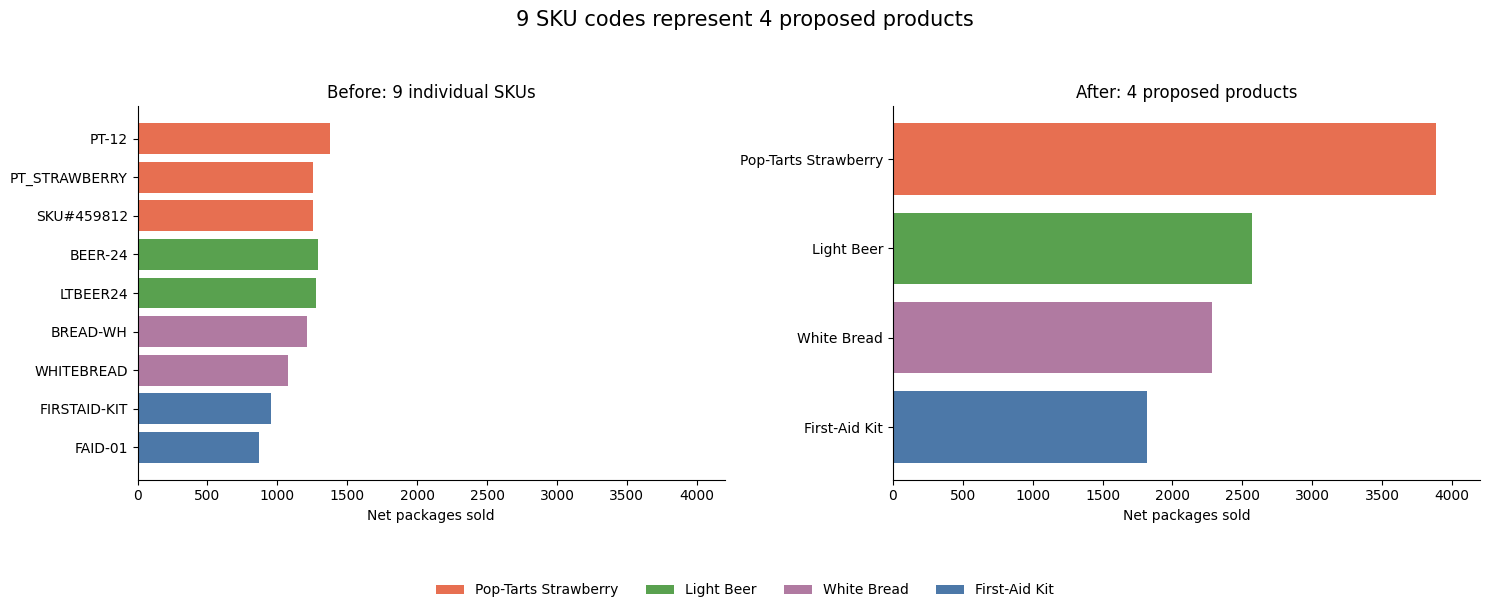

Original SKUs: 45
Proposed canonical products: 40
Total units preserved: 49343


In [42]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
mapping = catalog[["sku", "canonical_product"]].drop_duplicates()
sales = df_clean.merge(mapping, on="sku", how="left", validate="many_to_one")
assert sales["canonical_product"].notna().all()
assert sales["quantity"].sum() == df_clean["quantity"].sum()

families = mapping.groupby("canonical_product")["sku"].nunique()
fragmented = families[families > 1].index

names = {
    "poptartstrawberry_4-pack": "Pop-Tarts Strawberry",
    "firstaidkit_4-pack": "First-Aid Kit",
    "lightbeer24pack_bundle": "Light Beer",
    "whitebread_24-pack": "White Bread"
}

colors = {
    "poptartstrawberry_4-pack": "#E76F51",
    "firstaidkit_4-pack": "#4C78A8",
    "lightbeer24pack_bundle": "#59A14F",
    "whitebread_24-pack": "#B07AA1"
}

subset = sales[sales["canonical_product"].isin(fragmented)]
individual = subset.groupby(
    ["canonical_product", "sku"]
)["quantity"].sum()
combined = subset.groupby("canonical_product")["quantity"].sum()

# groupingn related SKUs together
order = sorted(fragmented, key=lambda f: combined[f], reverse=True)
sku_labels, sku_values, sku_colors = [], [], []
for family in order:
    family_skus = individual[family].sort_values(ascending=False)
    for sku, units in family_skus.items():
        sku_labels.append(sku)
        sku_values.append(units)
        sku_colors.append(colors[family])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# before individual SKUs
axes[0].barh(sku_labels, sku_values, color=sku_colors)
axes[0].invert_yaxis()
axes[0].set_title(f"Before: {len(sku_labels)} individual SKUs")

# consolidated products
axes[1].barh(
    [names[f] for f in order],
    [combined[f] for f in order],
    color=[colors[f] for f in order]
)
axes[1].invert_yaxis()
axes[1].set_title(f"After: {len(order)} proposed products")

for ax in axes:
    ax.set_xlabel("Net packages sold")
    ax.set_xlim(left=0, right=4200)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

#  legend
legend = [
    Patch(facecolor=colors[f], label=names[f])
    for f in order
]

fig.legend(
    handles=legend,
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.02),
    frameon=False
)

fig.suptitle(
    f"{len(sku_labels)} SKU codes represent {len(order)} proposed products",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.10, 1, 0.94])
plt.show()

print("Original SKUs:", mapping["sku"].nunique())
print("Proposed canonical products:", mapping["canonical_product"].nunique())
print("Total units preserved:", sales["quantity"].sum())

Our analysis identified **45 original SKUs representing 40 potentially distinct products**. We found four product groups with potentially duplicate identifiers: Pop-Tarts Strawberry, First-Aid Kits, Light Beer, and White Bread. The largest group was Pop-Tarts Strawberry 4-packs, which appeared under three different SKU codes, while the other three groups each appeared under two.

The graph illustrates how separate SKU identifiers can obscure the total demand for a product. Before consolidation, sales were distributed across nine individual SKUs. After grouping potentially equivalent products, we could observe the combined sales of four product groups. For example, each Pop-Tarts SKU recorded approximately 1,300 packages sold, but together they accounted for nearly **3,900 packages, or 2.82 times the sales of the highest-selling individual SKU**. Examining daily sales after consolidation also allows us to measure total Pop-Tarts demand across all three identifiers and identify purchasing spikes that might be overlooked when analyzing each SKU separately.

Consolidation did not increase actual sales. Our validation confirmed that the dataset's **49,343 net units sold remained unchanged**. Instead, consolidation provided a clearer picture of product demand. This matters because Walmart could underestimate demand and allocate insufficient inventory if it analyzed each SKU separately, particularly when preparing for increased purchasing ahead of hurricanes. More accurate demand estimates could improve inventory replenishment, distribution planning, and product availability. However, the proposed mappings should be verified against product and supplier information before permanently combining the identifiers.

SKU Revenue Across 4 Proposed Product Groups

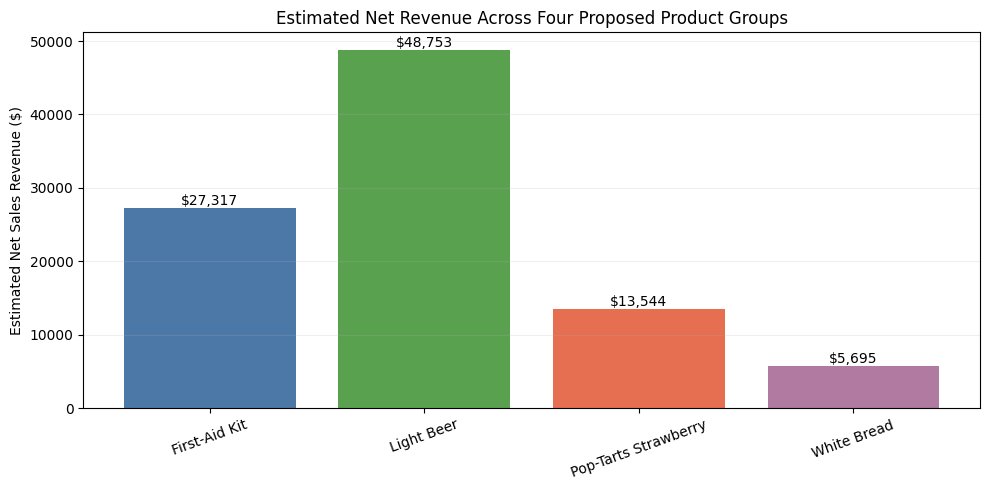

In [43]:
revenue = sales[sales["canonical_product"].isin(fragmented)].copy()
revenue["sales_revenue"] = revenue["quantity"] * revenue["unit_price"]
totals = revenue.groupby("canonical_product")["sales_revenue"].sum()
labels = [names.get(x, x) for x in totals.index]
plt.figure(figsize=(10, 5))
bars = plt.bar(labels, totals.values, color=[colors[x] for x in totals.index])
plt.title("Estimated Net Revenue Across Four Proposed Product Groups")
plt.ylabel("Estimated Net Sales Revenue ($)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.2)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'${bar.get_height():,.0f}', ha="center", va="bottom")

plt.tight_layout()
plt.show()

To understand the financial implications of SKU consolidation, we also calculated estimated sales revenue for the four fragmented product groups. Light Beer generated the highest estimated revenue at $48,753, followed by First-Aid Kits at $27,317, Pop-Tarts Strawberry at $13,544, and White Bread at $5,695.

Although Pop-Tarts had the highest combined sales volume among these four groups, Light Beer generated substantially more revenue. This illustrates why Walmart should consider both sales quantities and revenue when making inventory decisions. Sales volume helps determine how much inventory is needed to meet customer demand, while revenue helps Walmart assess the financial significance of each product. By consolidating fragmented SKUs, Walmart can more accurately evaluate product performance, prioritize replenishment, and allocate inventory across stores without changing the underlying transactions or prices.

Calculating daily Pop-Tarts sales:

In [44]:
# filtering for consolidated Strawberry Pop-Tarts
poptarts = sales[
    sales["canonical_product"] == "poptartstrawberry_4-pack"
].copy()
poptarts_daily = poptarts.dropna(subset=["timestamp"]).copy()
poptarts_daily["date"] = poptarts_daily["timestamp"].dt.date

# calculating daily sales by original SKU
daily_skus = (
    poptarts_daily.groupby(["date", "sku"])["quantity"]
    .sum()
    .unstack(fill_value=0)
)

# combining all three skus into daily totals
daily_skus["Consolidated Total"] = daily_skus.sum(axis=1)

display(daily_skus)

# daily totals against transactions with valid dates
assert daily_skus["Consolidated Total"].sum() == poptarts_daily["quantity"].sum()

print("Total Pop-Tarts packages with valid dates:",
      daily_skus["Consolidated Total"].sum())
print("Pop-Tarts packages without valid dates:",
      poptarts.loc[poptarts["timestamp"].isna(), "quantity"].sum())

sku,PT-12,PT_STRAWBERRY,SKU#459812,Consolidated Total
date,,,,
2024-09-01,16,18,15,49
2024-09-02,34,14,17,65
2024-09-03,28,22,8,58
2024-09-04,17,13,15,45
2024-09-05,33,44,43,120
2024-09-06,33,40,51,124
2024-09-07,48,38,50,136
2024-09-08,35,43,43,121
2024-09-09,32,60,28,120


Total Pop-Tarts packages with valid dates: 3752
Pop-Tarts packages without valid dates: 132


Daily Sales Visualization:

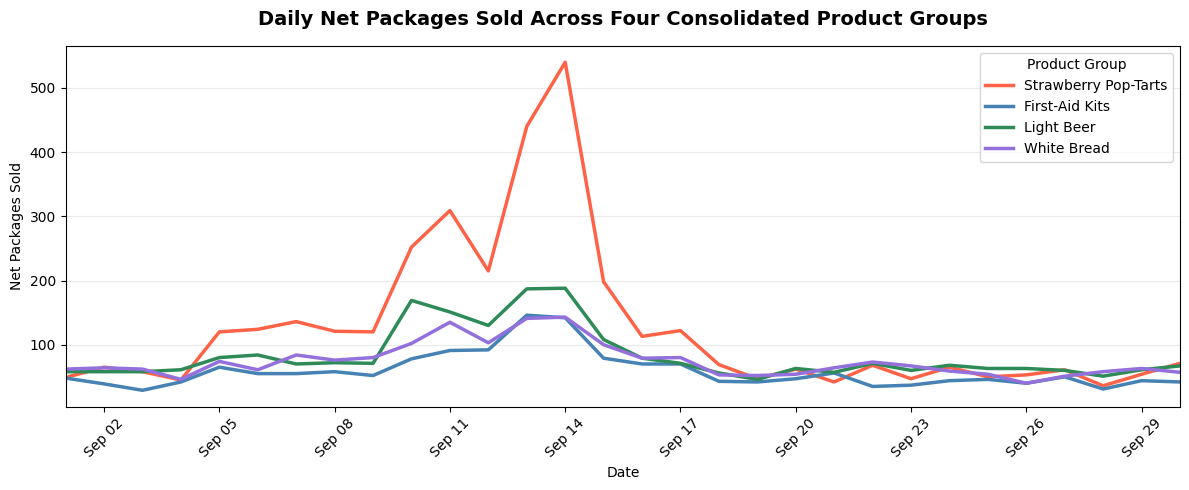

In [45]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
#  product names
names = {
    "poptartstrawberry_4-pack": "Strawberry Pop-Tarts",
    "firstaidkit_4-pack": "First-Aid Kits",
    "lightbeer24pack_bundle": "Light Beer",
    "whitebread_24-pack": "White Bread"
}

colors = {
    "Strawberry Pop-Tarts": "tomato",
    "First-Aid Kits": "steelblue",
    "Light Beer": "seagreen",
    "White Bread": "mediumpurple"
}

# matchings skus to their consolidated product groups
mapping = catalog[["sku", "canonical_product"]].drop_duplicates()

sales = df_clean.merge(
    mapping,
    on="sku",
    how="left",
    validate="many_to_one"
)

# converting timestamps to dates
sales["date"] = pd.to_datetime(
    sales["timestamp"], errors="coerce"
).dt.normalize()

# daily net packages sold
daily_comparison = (
    sales[
        sales["canonical_product"].isin(names.keys())
        & sales["date"].notna()
    ]
    .groupby(["date", "canonical_product"])["quantity"]
    .sum()
    .unstack(fill_value=0)
)

# every day in September
daily_comparison = daily_comparison.reindex(
    index=pd.date_range("2024-09-01", "2024-09-30"),
    columns=list(names.keys()),
    fill_value=0
)

daily_comparison = daily_comparison.rename(columns=names)

#  graph
fig, ax = plt.subplots(figsize=(12, 5))
for product in daily_comparison.columns:
    ax.plot(
        daily_comparison.index,
        daily_comparison[product],
        label=product,
        color=colors[product],
        linewidth=2.5
    )

ax.set_title(
    "Daily Net Packages Sold Across Four Consolidated Product Groups",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Date")
ax.set_ylabel("Net Packages Sold")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(title="Product Group")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=45)
ax.set_xlim(pd.Timestamp("2024-09-01"), pd.Timestamp("2024-09-30"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout()
plt.show()

The daily net packages sold analysis demonstrates how SKU fragmentation can obscure changes in product demand. Across the entire month of September 2024, the three Strawberry Pop-Tarts SKUs accounted for 3,884 net packages sold. Of these, 3,752 packages had valid transaction dates and could be included in the daily analysis, while the remaining 132 packages had missing timestamps. After consolidating the three SKUs, daily net packages sold increased from 49 on September 1 to a peak of 540 on September 14, approximately eleven times the September 1 volume. The 540 packages represent the combined number sold on September 14 alone and are already included in the monthly total of 3,884 packages. On that day, the three individual SKUs accounted for 240, 161, and 139 net packages sold, respectively. Analyzing these identifiers separately would therefore underestimate total daily demand for Strawberry Pop-Tarts and make the purchasing spike less apparent. Following the September 14 peak, daily net packages sold declined sharply to 198 on September 15 and generally remained lower for the rest of the month, suggesting a temporary increase in purchasing activity. Additionally, the 132 packages with missing timestamps came from 54 transactions and represented approximately 3.4% of the monthly Pop-Tarts total. These packages were preserved in the overall monthly total but excluded from the daily analysis because their purchase dates could not be determined. By consolidating equivalent SKUs and monitoring daily net packages sold, Walmart could more accurately identify sudden increases in product demand and make better-informed inventory replenishment decisions. However, additional weather data would be necessary to determine whether the observed purchasing spike was associated with hurricane conditions.

# Q5 Signal or Artifact

I could not complete this since my teammate did not do the API join.

# Reflections

1. Data Quality Impact: One significant data quality issue I encountered was the presence of duplicate transaction records. During cleaning, I identified and removed 30 exact duplicates, which accounted for 59 units of sales. This reduced the dataset from 25,562 to 25,532 transactions and corrected the total net quantity from 49,402 to 49,343 units. Although the difference may seem relatively small, retaining duplicate records would have inflated sales figures and potentially affected product demand estimates. This was especially relevant to my analysis of SKU consolidation, where accurately measuring sales quantities was essential. By removing duplicates and documenting the decision, I ensured that subsequent calculations reflected the actual recorded transactions without double-counting.

2. ETL Trade-offs: ne important decision I made during the ETL process was how to handle missing timestamps. I identified 884 transactions with missing timestamps and decided to retain these records while flagging them for transparency. An alternative approach would have been to remove every transaction without a valid date, which would have simplified daily sales analysis but excluded potentially legitimate sales from the dataset. For example, in my analysis of Strawberry Pop-Tarts, 54 transactions representing 132 packages had missing timestamps. Removing these transactions would have reduced the reported total from 3,884 to 3,752 packages, underestimating overall demand by approximately 3.4%. My approach preserved the transactions for aggregate sales calculations while excluding them from date-specific analyses. This allowed me to maintain accurate overall sales figures without assigning unsupported dates to transactions.

3. Pipeline Trust: I agree with the Walmart CDO's argument that the data pipeline can pose a greater risk than the analytical model itself. My experience demonstrated how inconsistencies introduced during data collection and storage can influence the conclusions drawn from otherwise correct calculations. The most fragile part of my pipeline was identifying potentially equivalent products recorded under different SKU codes. I identified 45 original SKUs that could potentially be consolidated into 40 products, including three separate identifiers for Strawberry Pop-Tarts. When analyzed individually, these identifiers made overall product demand less apparent. For example, consolidated Pop-Tarts sales reached 540 packages on September 14, while the three individual SKUs recorded 240, 161, and 139 packages. This discrepancy illustrates how even a technically correct analysis can produce misleading business interpretations when product identifiers are fragmented. I therefore preserved the original SKU identifiers and treated the proposed consolidations as provisional until they could be verified against product information.

4. Business vs. Data: I was assigned Question 5, which required evaluating board-game inventory and making a recommendation based on imperfect data. However, I was unable to complete this analysis because my teammate did not complete the API join that my portion of the project depended on. Without the necessary integrated data, I could not confidently evaluate the statistical evidence or make a defensible business recommendation. I would have considered both the available sales patterns and the financial risks associated with inventory decisions, including the possibility of overstocking products with limited demand or understocking products with stronger demand. With additional time and access to the completed data integration, I would have conducted the analysis, examined the reliability of the findings, and evaluated the potential consequences of different inventory decisions before making a recommendation. This experience demonstrated how incomplete upstream work can prevent subsequent analyses from being completed, even when responsibilities have been clearly assigned.

5. Team Collaboration: Our team initially divided project responsibilities, and I was assigned data cleaning, documentation of cleaning decisions, Question 2, and Question 5. I independently completed the data cleaning pipeline, documented nine cleaning decisions, validated the cleaned datasets, and conducted the SKU consolidation, revenue, and daily net packages sold analyses for Question 2. Unfortunately, my teammate did not complete her assigned responsibilities, including the weather API integration necessary for my planned Question 5 analysis, and eventually stopped responding to my messages. Despite frequent communication and regular progress check-ins on my end, I was unable to complete Question 5 as intended because it depended on her unfinished work. If I had another week, I would prioritize completing the weather API integration myself and finishing Question 5. I would also establish a contingency plan for tasks dependent on another team member, allowing responsibilities to be reassigned when communication breaks down. My primary contributions involved data cleaning, validation, documentation, and analysis, with an emphasis on producing accurate and reproducible results. Unfortunately, I cannot identify a specific skill my teammate contributed because she did not provide completed work or participate as expected. This experience reinforced the importance of accountability, consistent communication, and having backup plans when project responsibilities are interconnected.